# TP6 — Optimiser (2/2) : hyperparamètres et compression
**ÉNONCÉ** · Durée estimée : **une journée**

## 🎯 Ce que vous allez apprendre
- Distinguer **paramètres** (appris) et **hyperparamètres** (choisis par vous)
- Faire une **recherche aléatoire** d'hyperparamètres, et la **valider** sur plusieurs graines
- **Compresser** un modèle : élagage (pruning) et quantification (TensorFlow Lite)
- Juger un **compromis précision / taille**, avec des chiffres

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`random.choice`  ·  `random.seed`  ·  `pd.DataFrame.sort_values`  ·  `keras_tuner.RandomSearch`  ·  `np.quantile`  ·  `clone_model`  ·  `set_weights`  ·  `tf.lite.TFLiteConverter`  ·  `tf.lite.Interpreter`  ·  `os.path.getsize`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [25]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
import keras
from keras import layers, regularizers
import keras_tuner as kt

keras.utils.set_random_seed(42)
import random, tensorflow as tf

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Préparer : un jeu de validation et une fonction d'essai
Pour choisir des hyperparamètres, on compare **sur un jeu de validation, jamais sur le test** : sinon le test n'est plus « jamais vu » et son verdict est faussé. On découpe donc l'apprentissage en deux. La fonction `essayer` entraîne un réseau avec les réglages donnés et renvoie sa **précision de validation**.

In [4]:
from sklearn.datasets import load_digits
chiffres = load_digits()
X = chiffres.data / 16.0
y = chiffres.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

def essayer(neurones=32, couches=2, dropout=0.0, lr=1e-3, batch=32, seed=42):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([layers.Input(shape=(64,))])
    for _ in range(couches):
        m.add(layers.Dense(neurones, activation="relu"))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(10, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    m.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=40, batch_size=batch, callbacks=[arret], verbose=0)
    acc_val = float(np.mean(np.argmax(m.predict(X_val, verbose=0), axis=1) == y_val))
    return acc_val, m

acc_val_defaut, _ = essayer()
bruit_val = 1.96 * np.sqrt(acc_val_defaut * (1 - acc_val_defaut) / len(y_val))
print(f"Réglage par défaut : précision de validation = {acc_val_defaut:.3f}")
print(f"Avec {len(y_val)} images de validation, une différence inférieure à environ {bruit_val:.3f} est dans le bruit.")

Réglage par défaut : précision de validation = 0.952
Avec 270 images de validation, une différence inférieure à environ 0.026 est dans le bruit.


## 🎯 Étape 2 — Explorer le taux d'apprentissage
Le **taux d'apprentissage** est la taille du pas de chaque correction. C'est souvent **l'hyperparamètre le plus important**.

**À faire :** Avec `essayer`, testez les taux **0,0001 / 0,001 / 0,01 / 0,1** (autres réglages par défaut). Rangez les précisions de validation dans un dictionnaire `scores_lr` (clé = taux) et tracez-les (axe horizontal logarithmique).

> 💡 **Indice** : `plt.xscale("log")`. Une boucle `for lr in (...)`.

taux 0.0001  → précision de validation 0.867
taux 0.001   → précision de validation 0.952
taux 0.01    → précision de validation 0.959
taux 0.1     → précision de validation 0.726


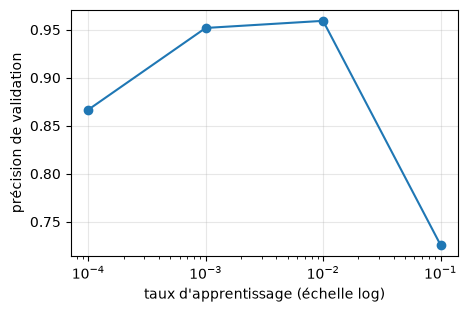

In [5]:
scores_lr = {}
for lr in (0.0001, 0.001, 0.01, 0.1):
    scores_lr[lr], _ = essayer(lr=lr)
    print(f"taux {lr:<7} → précision de validation {scores_lr[lr]:.3f}")

plt.figure(figsize=(5, 3.2))
plt.plot(list(scores_lr), list(scores_lr.values()), "o-")
plt.xscale("log")
plt.xlabel("taux d'apprentissage (échelle log)")
plt.ylabel("précision de validation")
plt.grid(alpha=0.3)
plt.show()

In [6]:
# ✅ Contrôle (ne pas modifier)
controle(len(scores_lr) == 4, '4 taux testés', 'Attendu 4 résultats')

✅ 4 taux testés


### ✍️ Question
**Que se passe-t-il aux deux extrêmes (taux très petit, taux très grand) ? Les écarts dépassent-ils le bruit mesuré plus haut ?**

*Réponse :*
> *Réponse rédigée avec vos résultats dans la cellule de code ci-dessous (exécutez-la).*

In [7]:
# ✍️ Réponse rédigée à partir de vos résultats
from IPython.display import Markdown, display

meilleur_lr = max(scores_lr, key=scores_lr.get)
ecart = max(scores_lr.values()) - min(scores_lr.values())
display(Markdown(
    f"> Avec un taux très petit (0,0001), les pas sont minuscules : le réseau apprend lentement et peut ne pas avoir le temps de converger (précision {scores_lr[0.0001]:.3f}). "
    f"Avec un taux très grand (0,1), les pas sont trop gros et l'apprentissage peut devenir instable (précision {scores_lr[0.1]:.3f}). "
    f"Le meilleur taux est {meilleur_lr} ({scores_lr[meilleur_lr]:.3f}) ; l'écart entre le meilleur et le pire ({ecart:.3f}) {'dépasse' if ecart > bruit_val else 'ne dépasse pas'} le bruit de validation (≈ {bruit_val:.3f})."
))

> Avec un taux très petit (0,0001), les pas sont minuscules : le réseau apprend lentement et peut ne pas avoir le temps de converger (précision 0.867). Avec un taux très grand (0,1), les pas sont trop gros et l'apprentissage peut devenir instable (précision 0.726). Le meilleur taux est 0.01 (0.959) ; l'écart entre le meilleur et le pire (0.233) dépasse le bruit de validation (≈ 0.026).

## 🎯 Étape 3 — Recherche aléatoire
Tester toutes les combinaisons (une **grille**) explose vite : 4 × 3 × 5 × 3 × 3 = 540 réseaux. La **recherche aléatoire** en tire seulement quelques-unes au hasard, et marche souvent aussi bien à budget égal.

**À faire :** **D'abord**, tirez **15 configurations au hasard** (après `random.seed(0)`) dans une liste `configs`, parmi : `neurones` ∈ {16, 32, 64, 128}, `couches` ∈ {1, 2, 3}, `dropout` ∈ {0, 0.1, 0.2, 0.3, 0.5}, `lr` ∈ {0.001, 0.003, 0.01}, `batch` ∈ {16, 32, 64}. **Ensuite**, évaluez chacune avec `essayer`. Rangez le tout dans un tableau **`recherche`** (une colonne par réglage + `acc_val`), **trié par `acc_val` décroissant**. Vérifiez que vos 15 configurations sont bien **différentes**.

> 💡 **Indice** : `random.choice(liste)`. `pd.DataFrame(liste_de_dicts).sort_values(..., ascending=False)`. ⚠️ **Piège** : `keras.utils.set_random_seed` (appelé dans `essayer`) réinitialise **aussi** le module `random` de Python. Si vous tirez une configuration, puis entraînez, puis retirez, vous retomberez toujours sur la même. D'où l'ordre : tirer tout **avant** d'entraîner.

In [8]:
random.seed(0)
espace = {
    "neurones": [16, 32, 64, 128],
    "couches": [1, 2, 3],
    "dropout": [0, 0.1, 0.2, 0.3, 0.5],
    "lr": [0.001, 0.003, 0.01],
    "batch": [16, 32, 64],
}

# 1) d'abord tirer les 15 configurations (avant tout entraînement)
configs = [{nom: random.choice(valeurs) for nom, valeurs in espace.items()} for _ in range(15)]

# 2) ensuite les évaluer
lignes = []
for cfg in configs:
    acc, _ = essayer(**cfg)
    lignes.append({**cfg, "acc_val": acc})

recherche = pd.DataFrame(lignes).sort_values("acc_val", ascending=False).reset_index(drop=True)
recherche

,neurones,couches,dropout,lr,batch,acc_val
0,32,3,0.1,0.003,16,0.981481
1,128,2,0.5,0.003,16,0.981481
2,128,2,0.2,0.003,32,0.977778
3,64,3,0.0,0.001,64,0.977778
4,32,1,0.1,0.010,32,0.974074
5,128,2,0.5,0.010,16,0.970370
6,32,2,0.0,0.010,16,0.970370
7,64,2,0.5,0.001,32,0.962963
8,16,1,0.2,0.010,32,0.959259
9,16,1,0.3,0.010,64,0.955556


In [9]:
# ✅ Contrôle (ne pas modifier)
nb_differentes = len(recherche.drop(columns='acc_val').drop_duplicates())
controle(len(recherche) == 15 and recherche['acc_val'].is_monotonic_decreasing and nb_differentes >= 12, '15 essais triés, %d configurations différentes' % nb_differentes, 'Attendu 15 lignes triées et au moins 12 configurations différentes (avez-vous tiré avant d\'entraîner ?)')

✅ 15 essais triés, 15 configurations différentes


### ✍️ Question
**Quel écart y a-t-il entre le meilleur et le pire essai ? Le meilleur est-il réellement meilleur que le réglage par défaut, compte tenu du bruit ?**

*Réponse :*
> *Réponse rédigée avec vos résultats dans la cellule de code ci-dessous (exécutez-la).*

In [10]:
# ✍️ Réponse rédigée à partir de vos résultats
from IPython.display import Markdown, display

meilleur_acc, pire_acc = recherche["acc_val"].max(), recherche["acc_val"].min()
gain_vs_defaut = meilleur_acc - acc_val_defaut
au_dessus = gain_vs_defaut > bruit_val
display(Markdown(
    f"> Le meilleur essai obtient {meilleur_acc:.3f} et le pire {pire_acc:.3f}, soit un écart de {meilleur_acc - pire_acc:.3f}. "
    f"Le meilleur dépasse le réglage par défaut ({acc_val_defaut:.3f}) de {gain_vs_defaut:+.3f}, un gain {'supérieur' if au_dessus else 'inférieur'} au bruit de validation (≈ {bruit_val:.3f}) : "
    + ("il est probablement un peu meilleur, à confirmer sur plusieurs graines." if au_dessus
       else "il n'est donc pas démontré meilleur, il a pu avoir de la chance.")
))

> Le meilleur essai obtient 0.981 et le pire 0.900, soit un écart de 0.081. Le meilleur dépasse le réglage par défaut (0.952) de +0.030, un gain supérieur au bruit de validation (≈ 0.026) : il est probablement un peu meilleur, à confirmer sur plusieurs graines.

## Étape 4 — Bonus : la même recherche avec Keras Tuner
Un outil dédié automatise la recherche et garde la trace des essais. **À installer** : `pip install keras-tuner tensorboard`. Cette cellule est un bonus : si elle ne s'exécute pas, la suite du TP n'en dépend pas.

In [11]:
def construire_hp(hp):
    m = keras.Sequential()
    m.add(layers.Input(shape=(64,)))
    
    # Add hidden layers based on the tuned number of layers
    for _ in range(hp.Int("couches", 1, 3)):
        m.add(layers.Dense(hp.Choice("neurones", [16, 32, 64, 128]), activation="relu"))
        m.add(layers.Dropout(hp.Choice("dropout", [0.0, 0.1, 0.2, 0.3, 0.5])))
        
    # Output layer (placed OUTSIDE the loop so it's added only once at the end)
    m.add(layers.Dense(10, activation="softmax"))
    
    # Compile the model
    m.compile(
        optimizer=keras.optimizers.Adam(hp.Choice("lr", [1e-3, 3e-3, 1e-2])), 
        loss="sparse_categorical_crossentropy", 
        metrics=["accuracy"]
    )
    return m

# --- Tuner setup (MUST be outside the function) ---
tuner = kt.RandomSearch(
    construire_hp, 
    objective="val_accuracy", 
    max_trials=10, 
    seed=0, 
    directory="kt_tp6", 
    project_name="digits", 
    overwrite=True
)

# Run the search (Assumes X_tr, y_tr, X_val, y_val are defined in your notebook/script)
tuner.search(
    X_tr, y_tr, 
    validation_data=(X_val, y_val), 
    epochs=30, 
    batch_size=32,
    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)], 
    verbose=1  # Set to 1 so you can see the progress of the search trials
)

# Print results
print("Meilleurs hyperparamètres trouvés par Keras Tuner :", tuner.get_best_hyperparameters(1)[0].values)

Trial 10 Complete [00h 00m 05s]
val_accuracy: 0.970370352268219

Best val_accuracy So Far: 0.9814814925193787
Total elapsed time: 00h 01m 11s
Meilleurs hyperparamètres trouvés par Keras Tuner : {'couches': 2, 'neurones': 64, 'dropout': 0.3, 'lr': 0.003}


## 🎯 Étape 5 — Valider sur plusieurs graines
Le meilleur essai de la recherche a pu avoir de la **chance**. Pour le savoir, on **répète** : la meilleure configuration et la configuration par défaut, **5 fois chacune** avec des graines différentes.

**À faire :** Récupérez la meilleure configuration de `recherche` (1re ligne) dans `meilleure` (dictionnaire des 5 réglages, sans `acc_val`). Avec `essayer`, calculez les précisions de validation de la configuration par défaut (`scores_defaut`) puis de la meilleure (`scores_meilleure`) pour les graines **0 à 4**. Calculez `gain` (différence des moyennes) et affichez une **conclusion automatique** : « réel » si `gain > bruit_val`, sinon « dans le bruit ».

> 💡 **Indice** : `recherche.iloc[0]`, `.to_dict()`. Attention aux types : `int(...)` pour `neurones`, `couches`, `batch`.

In [12]:
meilleure = recherche.iloc[0].drop("acc_val").to_dict()
for cle in ("neurones", "couches", "batch"):
    meilleure[cle] = int(meilleure[cle])
print("Meilleure configuration :", meilleure)

scores_defaut = [essayer(seed=s)[0] for s in range(5)]
scores_meilleure = [essayer(seed=s, **meilleure)[0] for s in range(5)]

gain = np.mean(scores_meilleure) - np.mean(scores_defaut)
print(f"Défaut   : {np.mean(scores_defaut):.3f} ± {np.std(scores_defaut):.3f}")
print(f"Meilleure : {np.mean(scores_meilleure):.3f} ± {np.std(scores_meilleure):.3f}")
print(f"Gain moyen : {gain:+.3f} (bruit de validation ≈ {bruit_val:.3f})")
print("Conclusion :", "réel" if gain > bruit_val else "dans le bruit")

Meilleure configuration : {'neurones': 32, 'couches': 3, 'dropout': 0.1, 'lr': 0.003, 'batch': 16}
Défaut   : 0.967 ± 0.005
Meilleure : 0.964 ± 0.013
Gain moyen : -0.002 (bruit de validation ≈ 0.026)
Conclusion : dans le bruit


In [22]:
# ✅ Contrôle (ne pas modifier)
controle(len(scores_defaut) == 5 and len(scores_meilleure) == 5 and 'neurones' in meilleure, 'Deux séries de 5 graines', 'Attendu 5 valeurs dans chaque liste et un dictionnaire meilleure')

✅ Deux séries de 5 graines


### ✍️ Question
**L'optimisation d'hyperparamètres a-t-elle apporté un gain démontré ? Est-ce un échec si ce n'est pas le cas ?**

*Réponse :*
> *Réponse rédigée avec vos résultats dans la cellule de code ci-dessous (exécutez-la).*

In [23]:
# ✍️ Réponse rédigée à partir de vos résultats
from IPython.display import Markdown, display

reel = gain > bruit_val
display(Markdown(
    f"> {'Oui' if reel else 'Non'} : sur 5 graines, la meilleure configuration obtient {np.mean(scores_meilleure):.3f} contre {np.mean(scores_defaut):.3f} pour le réglage par défaut, "
    f"soit un gain de {gain:+.3f} ({'au-dessus du' if reel else 'dans le'} bruit de {bruit_val:.3f}). "
    + ("L'optimisation a donc apporté un gain réel, à confirmer sur le test." if reel
       else "Ce n'est pas un échec : cela montre que le réglage par défaut est déjà bon, et on évite de croire à une amélioration due à la chance.")
))

> Non : sur 5 graines, la meilleure configuration obtient 0.964 contre 0.967 pour le réglage par défaut, soit un gain de -0.002 (dans le bruit de 0.026). Ce n'est pas un échec : cela montre que le réglage par défaut est déjà bon, et on évite de croire à une amélioration due à la chance.

## 🎯 Étape 6 — Évaluer le modèle final, une seule fois sur le test
On entraîne la meilleure configuration retenue, puis on mesure **une seule fois** sur le jeu de test, resté intact jusqu'ici.

**À faire :** Entraînez la meilleure configuration avec `essayer(**meilleure)` (graine 42) pour obtenir `modele_final`. Calculez `acc_test_final` sur `X_test`.

> 💡 **Indice** : `essayer` renvoie un couple `(précision de validation, modèle)`.

In [15]:
_, modele_final = essayer(**meilleure)
acc_test_final = float(np.mean(np.argmax(modele_final.predict(X_test, verbose=0), axis=1) == y_test))
print(f"Précision test du modèle final : {acc_test_final:.3f}")

Précision test du modèle final : 0.978


In [16]:
# ✅ Contrôle (ne pas modifier)
controle(acc_test_final > 0.9, 'Modèle final : %.3f sur le test' % acc_test_final, 'Attendu plus de 0.9')

✅ Modèle final : 0.978 sur le test


## 🎯 Étape 7 — Compression 1 : l'élagage
L'**élagage** (pruning) met à zéro les poids les plus proches de zéro : ils contribuent peu. Un modèle avec beaucoup de zéros peut être stocké et calculé plus efficacement. Jusqu'où peut-on aller sans perdre en précision ?

**À faire :** Pour des taux **0, 50, 80, 90 et 95 %**, mettez à zéro les poids (matrices seulement, pas les biais) dont la **valeur absolue est sous le quantile** correspondant, puis mesurez la précision test du modèle élagué. Rangez dans un dictionnaire `resultats_elagage` (clé = taux, de 0 à 0.95).

> 💡 **Indice** : `modele_final.get_weights()` renvoie une liste ; les matrices ont `ndim == 2`. `np.quantile(np.abs(...), taux)`. Pour évaluer un jeu de poids : `keras.models.clone_model(modele_final)` puis `set_weights`.

In [17]:
poids = modele_final.get_weights()
resultats_elagage = {}

for taux in (0, 0.5, 0.8, 0.9, 0.95):
    nouveaux = []
    for w in poids:
        if w.ndim == 2 and taux > 0:            # matrices seulement, pas les biais
            seuil = np.quantile(np.abs(w), taux)
            w = np.where(np.abs(w) < seuil, 0.0, w)
        nouveaux.append(w)
    m = keras.models.clone_model(modele_final)
    m.set_weights(nouveaux)
    resultats_elagage[taux] = float(np.mean(np.argmax(m.predict(X_test, verbose=0), axis=1) == y_test))
    print(f"élagage {taux:>4.0%} → précision test {resultats_elagage[taux]:.3f}")

élagage   0% → précision test 0.978
élagage  50% → précision test 0.949
élagage  80% → précision test 0.373
élagage  90% → précision test 0.096
élagage  95% → précision test 0.100


In [18]:
# ✅ Contrôle (ne pas modifier)
controle(abs(resultats_elagage[0] - acc_test_final) < 1e-9 and resultats_elagage[0.95] <= resultats_elagage[0], 'Élagage cohérent : 0 % = modèle original', 'Attendu : 0 % identique au modèle final, et 95 % pas meilleur')

✅ Élagage cohérent : 0 % = modèle original


## 🎯 Étape 8 — Compression 2 : la quantification
La **quantification** stocke les poids sur **8 bits entiers** au lieu de 32 bits décimaux : le fichier est environ **4 fois plus petit** et le calcul plus rapide. C'est la technique de compression la plus utilisée. TensorFlow Lite la fait en quelques lignes.

**À faire :** Convertissez `modele_final` en modèle TensorFlow Lite quantifié (`tf.lite.Optimize.DEFAULT`). Mesurez `taille_keras` (taille en octets du modèle sauvegardé au format `.keras`) et `taille_tflite`. Vérifiez la précision du modèle quantifié sur le test avec l'interpréteur TFLite : `acc_tflite`.

> 💡 **Indice** : `modele_final.save("fichier.keras")`, `os.path.getsize`. `tf.lite.TFLiteConverter.from_keras_model`, `.optimizations`, `.convert()`. `tf.lite.Interpreter(model_content=...)`, `allocate_tensors`, `set_tensor`, `invoke`, `get_tensor`.

In [19]:
# 1. Taille du modèle Keras
modele_final.save("modele_final.keras")
taille_keras = os.path.getsize("modele_final.keras")

# 2. Conversion en TensorFlow Lite quantifié
convertisseur = tf.lite.TFLiteConverter.from_keras_model(modele_final)
convertisseur.optimizations = [tf.lite.Optimize.DEFAULT]
modele_tflite = convertisseur.convert()
taille_tflite = len(modele_tflite)

# 3. Précision du modèle quantifié sur le test
interpreteur = tf.lite.Interpreter(model_content=modele_tflite)
interpreteur.allocate_tensors()

entree = interpreteur.get_input_details()[0]["index"]
sortie = interpreteur.get_output_details()[0]["index"]

predictions = []
for x in X_test:
    interpreteur.set_tensor(entree, x.reshape(1, -1).astype(np.float32))
    interpreteur.invoke()
    predictions.append(int(np.argmax(interpreteur.get_tensor(sortie)[0])))

acc_tflite = float(np.mean(np.array(predictions) == y_test))

# 4. Affichage des résultats
print(f"Taille .keras  : {taille_keras / 1024:.1f} Ko")
print(f"Taille TFLite  : {taille_tflite / 1024:.1f} Ko")
print(f"Précision test : {acc_test_final:.3f} (Keras) → {acc_tflite:.3f} (TFLite quantifié)")

INFO:tensorflow:Assets written to: /tmp/tmp7su2i49y/assets


INFO:tensorflow:Assets written to: /tmp/tmp7su2i49y/assets


Saved artifact at '/tmp/tmp7su2i49y'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64), dtype=tf.float32, name='keras_tensor_209')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  125992016421776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  125992016422544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  125992016422352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  125992016422736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  125992016423504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  125992016416400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  125992016425232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  125992016423312: TensorSpec(shape=(), dtype=tf.resource, name=None)
Taille .keras  : 89.3 Ko
Taille TFLite  : 9.6 Ko
Précision test : 0.978 (Keras) → 0.978 (TFLite quantifié)


/root/.pyenv/versions/3.11.13/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [24]:
# ✅ Contrôle (ne pas modifier)
controle(taille_tflite < taille_keras and abs(acc_tflite - acc_test_final) < 0.03, 'Modèle plus petit, précision conservée', 'Attendu : un fichier plus petit et une précision proche (écart < 0.03)')

✅ Modèle plus petit, précision conservée


### ✍️ Question
**Quel compromis choisiriez-vous entre taille, vitesse et précision pour mettre ce modèle en production ? Justifiez avec vos chiffres.**

*Réponse :*
> *Réponse rédigée avec vos résultats dans la cellule de code ci-dessous (exécutez-la).*

In [21]:
# ✍️ Réponse rédigée à partir de vos résultats
from IPython.display import Markdown, display

rapport = taille_keras / taille_tflite
tenue = "reste proche" if abs(acc_tflite - acc_test_final) < 0.03 else "baisse davantage (à surveiller)"
display(Markdown(
    f"> Je choisirais le **modèle quantifié (TFLite)** : il pèse {taille_tflite / 1024:.1f} Ko contre {taille_keras / 1024:.1f} Ko pour le fichier Keras (÷ {rapport:.1f}) "
    f"et sa précision test {tenue} ({acc_tflite:.3f} contre {acc_test_final:.3f}). "
    f"L'élagage seul ne réduit pas la taille du fichier (les zéros sont toujours stockés) : à 90 % il donne {resultats_elagage[0.9]:.3f}, à 95 % {resultats_elagage[0.95]:.3f}. "
    "Le calcul est aussi en général plus rapide avec des poids sur 8 bits (non mesuré ici)."
))

> Je choisirais le **modèle quantifié (TFLite)** : il pèse 9.6 Ko contre 89.3 Ko pour le fichier Keras (÷ 9.3) et sa précision test reste proche (0.978 contre 0.978). L'élagage seul ne réduit pas la taille du fichier (les zéros sont toujours stockés) : à 90 % il donne 0.096, à 95 % 0.100. Le calcul est aussi en général plus rapide avec des poids sur 8 bits (non mesuré ici).

## ✅ Ce qu'il faut retenir
- **Paramètres** = appris par le modèle. **Hyperparamètres** = choisis par vous (taux d'apprentissage, neurones, couches, dropout, batch…).
- On les compare **sur la validation, jamais sur le test**, et on **répète sur plusieurs graines**.
- Un gain ne compte que s'il dépasse le **bruit**. Ne pas trouver de gain est un résultat, pas un échec.
- **Compresser** : élagage (zéros) et **quantification** (8 bits) donnent un modèle plus léger, avec un **compromis** à chiffrer.
- Le jeu de test sert **une seule fois, à la fin**.

## 📋 Tableau de synthèse à compléter (compte rendu)
| Version du modèle | Précision test | Taille | Commentaire |
|---|---|---|---|
| Modèle de départ (défaut) |0.967 |±0.005 |bruit |
| Meilleure configuration |0.964 |±0.013 | dans le bruit|
| Élagué à 0%|0.978| | |
| Quantifié (TFLite) | 0.978|9.6 Ko | |